# Project 03: Customer Churn / Sales Trend Analysis

## The business question
A manager wants to know:
1. **Which months and categories earn the most?**
2. **Who are our best customers?**
3. **What should we do next?**

## Data and assumptions
I use a **generated (simulated) order table**, not real customer data: 2,000 orders from 300 customers across 2025 in four categories. Because it is simulated, differences between months or categories partly reflect chance, and the recommendations below show the *method* rather than real business facts.

## 1. Create the data and check it

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid", palette="colorblind")

rng = np.random.default_rng(42)
n = 2000
orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "customer_id": rng.integers(1, 301, n),
    "category": rng.choice(["Electronics", "Fashion", "Home", "Books"], n, p=[0.3, 0.35, 0.2, 0.15]),
    "amount": rng.gamma(2.0, 600, n).round(2),
})

print("Shape:", orders.shape)
print("Missing values:", int(orders.isna().sum().sum()))
print("Duplicate rows:", orders.duplicated().sum())
print(orders.dtypes)
orders.head()

Shape: (2000, 4)
Missing values: 0
Duplicate rows: 0
order_date     datetime64[us]
customer_id             int64
category                  str
amount                float64
dtype: object


,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


## 2. Add date features
Convert the date column (already a datetime) and create **month**, **weekday** and **quarter** columns.

In [2]:
orders["month"] = orders["order_date"].dt.to_period("M")
orders["weekday"] = orders["order_date"].dt.day_name()
orders["quarter"] = orders["order_date"].dt.quarter
orders.head()

,order_date,customer_id,category,amount,month,weekday,quarter
0,2025-02-02,264,Home,391.13,2025-02,Sunday,1
1,2025-10-10,19,Fashion,2456.21,2025-10,Friday,4
2,2025-08-27,120,Books,674.90,2025-08,Wednesday,3
3,2025-06-10,138,Home,75.38,2025-06,Tuesday,2
4,2025-06-08,240,Electronics,774.42,2025-06,Sunday,2


## 3. Analyse the trend

In [3]:
monthly = orders.groupby("month")["amount"].sum()
growth = (monthly.pct_change() * 100).round(1)

trend = pd.DataFrame({"revenue": monthly.round(0), "growth_%": growth})
best_m, worst_m = monthly.idxmax(), monthly.idxmin()
print("Best month: ", best_m, f"(${monthly.max():,.0f})")
print("Worst month:", worst_m, f"(${monthly.min():,.0f})")
trend

Best month:  2025-02 ($232,027)
Worst month: 2025-08 ($179,784)


,revenue,growth_%
month,,
2025-01,193342.0,NaN
2025-02,232027.0,20.0
2025-03,206327.0,-11.1
2025-04,197310.0,-4.4
2025-05,194090.0,-1.6
2025-06,221890.0,14.3
2025-07,221814.0,-0.0
2025-08,179784.0,-18.9
2025-09,180570.0,0.4


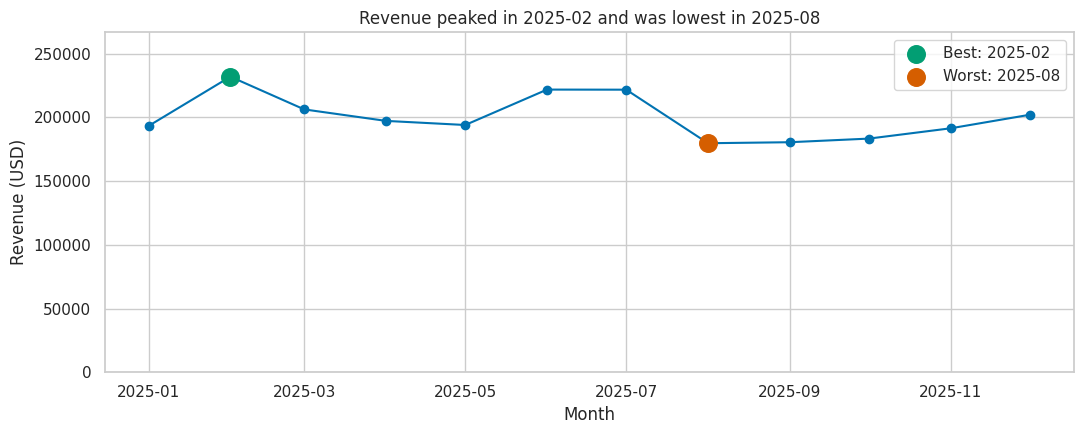

In [4]:
x = monthly.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(x, monthly.values, marker="o")
ax.scatter([best_m.to_timestamp()], [monthly.max()], s=160, color="#029E73", zorder=3, label=f"Best: {best_m}")
ax.scatter([worst_m.to_timestamp()], [monthly.min()], s=160, color="#D55E00", zorder=3, label=f"Worst: {worst_m}")
ax.set(title=f"Revenue peaked in {best_m} and was lowest in {worst_m}",
       xlabel="Month", ylabel="Revenue (USD)", ylim=(0, monthly.max() * 1.15))
ax.legend()
plt.tight_layout()
plt.savefig("monthly_revenue.png", dpi=150)
plt.show()

## 4. Compare categories

In [5]:
by_cat = (orders.groupby("category")["amount"].agg(["sum", "mean", "count"])
          .sort_values("sum", ascending=False).round(1))
by_cat["share_%"] = (by_cat["sum"] / by_cat["sum"].sum() * 100).round(1)
by_cat

,sum,mean,count,share_%
category,,,,
Fashion,853984.9,1220.0,700,35.5
Electronics,722645.5,1163.7,621,30.1
Home,464114.7,1218.1,381,19.3
Books,363488.2,1219.8,298,15.1


In [6]:
pivot = orders.pivot_table(index="month", columns="category", values="amount", aggfunc="sum").round(0)
pivot

category,Books,Electronics,Fashion,Home
month,,,,
2025-01,29187.0,62842.0,64666.0,36647.0
2025-02,34034.0,53565.0,86123.0,58305.0
2025-03,27844.0,58056.0,75139.0,45289.0
2025-04,26594.0,83336.0,57058.0,30323.0
2025-05,34426.0,57219.0,68570.0,33876.0
2025-06,32937.0,60037.0,85598.0,43318.0
2025-07,35582.0,72650.0,72648.0,40934.0
2025-08,32551.0,56690.0,71252.0,19291.0
2025-09,21825.0,60389.0,60232.0,38125.0


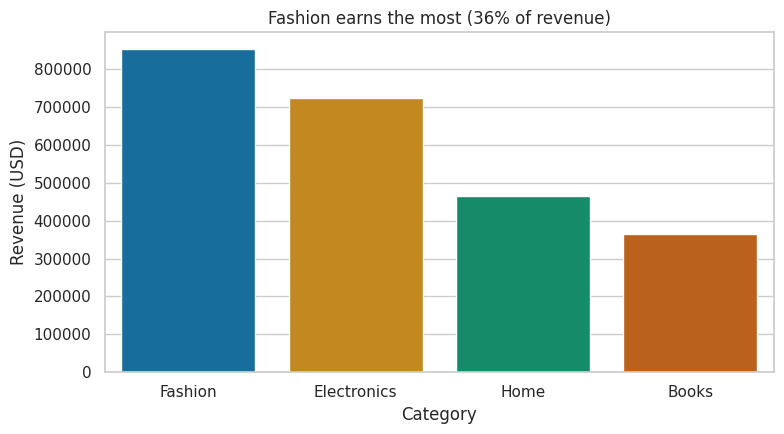

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=by_cat.index, y=by_cat["sum"], hue=by_cat.index, legend=False, ax=ax)
top_cat, top_share = by_cat.index[0], by_cat["share_%"].iloc[0]
ax.set(title=f"{top_cat} earns the most ({top_share:.0f}% of revenue)",
       xlabel="Category", ylabel="Revenue (USD)")
plt.tight_layout()
plt.savefig("category_revenue.png", dpi=150)
plt.show()

## 5. Find the best customers (the 80/20 idea)
What share of revenue comes from the top 10% of customers?

Customers: 300  |  Top 10% = 30 customers
Top 10% of customers bring 19% of revenue
It takes 190 customers (63%) to reach 80% of revenue


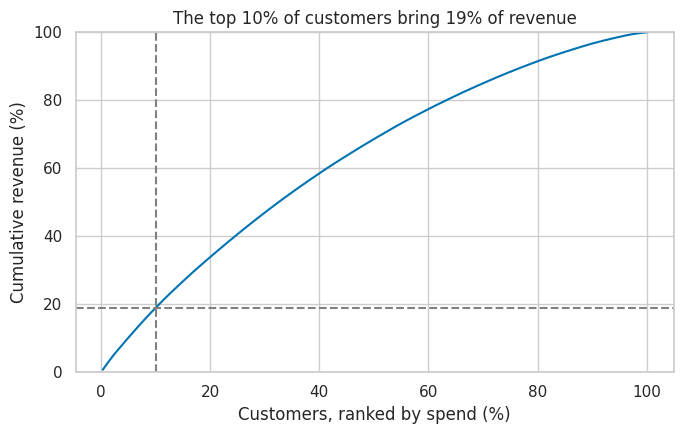

In [8]:
spend = orders.groupby("customer_id")["amount"].sum().sort_values(ascending=False)
top_n = len(spend) // 10
top_share_c = spend.head(top_n).sum() / spend.sum()
cum = spend.cumsum() / spend.sum()
n80 = int((cum < 0.8).sum() + 1)

print(f"Customers: {len(spend)}  |  Top 10% = {top_n} customers")
print(f"Top 10% of customers bring {top_share_c:.0%} of revenue")
print(f"It takes {n80} customers ({n80 / len(spend):.0%}) to reach 80% of revenue")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100)
ax.axvline(10, ls="--", color="grey")
ax.axhline(top_share_c * 100, ls="--", color="grey")
ax.set(title=f"The top 10% of customers bring {top_share_c:.0%} of revenue",
       xlabel="Customers, ranked by spend (%)", ylabel="Cumulative revenue (%)", ylim=(0, 100))
plt.tight_layout()
plt.savefig("top_customers.png", dpi=150)
plt.show()

## 6. Churn check (inactive customers)
I define a customer as **inactive (likely churned)** if they have not ordered in the last 90 days of the data. This is a simple rule, not a prediction model.

In [9]:
snapshot = orders["order_date"].max()
last_order = orders.groupby("customer_id")["order_date"].max()
days_since = (snapshot - last_order).dt.days
inactive = days_since > 90
n_inactive = int(inactive.sum())
inactive_rate = inactive.mean()
inactive_spend_avg = spend[inactive[inactive].index].mean()

print(f"Inactive customers (no order in 90+ days): {n_inactive} of {len(spend)} ({inactive_rate:.0%})")
print(f"Average past spend of inactive customers: ${inactive_spend_avg:,.0f}")

Inactive customers (no order in 90+ days): 52 of 300 (17%)
Average past spend of inactive customers: $6,032


## 7. Three recommendations, backed by numbers

In [10]:
worst_vs_best = (1 - monthly.min() / monthly.max()) * 100

recs = f"""
1. **Run a loyalty offer for the top 10% of customers, and keep it affordable.** These {top_n} customers bring **{top_share_c:.0%}** of revenue (about {top_share_c / 0.10:.1f} times their share of customers), but revenue is spread widely: it takes **{n80 / len(spend):.0%}** of customers to reach 80%. That is far from a strict 80/20 pattern, so also reward mid-spending customers.
2. **Win back inactive customers.** **{n_inactive}** customers ({inactive_rate:.0%}) have not ordered in 90+ days and spent about **${inactive_spend_avg:,.0f}** each on average before going quiet. Send them a targeted win-back offer.
3. **Focus stock and marketing on {top_cat}, and lift {worst_m}.** {top_cat} earns **{top_share:.0f}%** of revenue, and {worst_m} revenue was **{worst_vs_best:.0f}%** below the best month ({best_m}). Plan a campaign for the weakest month.
"""
display(Markdown(recs))


1. **Run a loyalty offer for the top 10% of customers, and keep it affordable.** These 30 customers bring **19%** of revenue (about 1.9 times their share of customers), but revenue is spread widely: it takes **63%** of customers to reach 80%. That is far from a strict 80/20 pattern, so also reward mid-spending customers.
2. **Win back inactive customers.** **52** customers (17%) have not ordered in 90+ days and spent about **$6,032** each on average before going quiet. Send them a targeted win-back offer.
3. **Focus stock and marketing on Fashion, and lift 2025-08.** Fashion earns **36%** of revenue, and 2025-08 revenue was **23%** below the best month (2025-02). Plan a campaign for the weakest month.


## 8. One-page business brief

In [11]:
brief = f"""# Business Brief: E-commerce Sales Analysis (2025)

## Context
A manager wants to know which months and categories earn the most, who the best customers are, and what to do next. This analysis uses a **simulated** order table (2,000 orders, 300 customers, four categories, 2025), so month-to-month differences partly reflect chance and the figures illustrate the method.

## Key findings
- **Total revenue:** ${orders['amount'].sum():,.0f} from {len(orders):,} orders; average order ${orders['amount'].mean():,.0f}.
- **Best / worst month:** {best_m} (${monthly.max():,.0f}) and {worst_m} (${monthly.min():,.0f}).
- **Top category:** {top_cat} with {top_share:.0f}% of revenue.
- **Best customers:** the top 10% of customers ({top_n} people) bring {top_share_c:.0%} of revenue; it takes {n80} customers ({n80 / len(spend):.0%}) to reach 80%.
- **Inactive customers:** {n_inactive} of {len(spend)} ({inactive_rate:.0%}) have not ordered in 90+ days.

## Recommendations
{recs.strip()}

## Next steps
1. Repeat this analysis on real sales data (with permission) to confirm the patterns.
2. Test the loyalty and win-back offers on a small group first and measure the response.
3. Track monthly revenue, inactive customers and top-10% share every month.
"""
Path("business_brief.md").write_text(brief, encoding="utf-8")
display(Markdown(brief))

# Business Brief: E-commerce Sales Analysis (2025)

## Context
A manager wants to know which months and categories earn the most, who the best customers are, and what to do next. This analysis uses a **simulated** order table (2,000 orders, 300 customers, four categories, 2025), so month-to-month differences partly reflect chance and the figures illustrate the method.

## Key findings
- **Total revenue:** $2,404,233 from 2,000 orders; average order $1,202.
- **Best / worst month:** 2025-02 ($232,027) and 2025-08 ($179,784).
- **Top category:** Fashion with 36% of revenue.
- **Best customers:** the top 10% of customers (30 people) bring 19% of revenue; it takes 190 customers (63%) to reach 80%.
- **Inactive customers:** 52 of 300 (17%) have not ordered in 90+ days.

## Recommendations
1. **Run a loyalty offer for the top 10% of customers, and keep it affordable.** These 30 customers bring **19%** of revenue (about 1.9 times their share of customers), but revenue is spread widely: it takes **63%** of customers to reach 80%. That is far from a strict 80/20 pattern, so also reward mid-spending customers.
2. **Win back inactive customers.** **52** customers (17%) have not ordered in 90+ days and spent about **$6,032** each on average before going quiet. Send them a targeted win-back offer.
3. **Focus stock and marketing on Fashion, and lift 2025-08.** Fashion earns **36%** of revenue, and 2025-08 revenue was **23%** below the best month (2025-02). Plan a campaign for the weakest month.

## Next steps
1. Repeat this analysis on real sales data (with permission) to confirm the patterns.
2. Test the loyalty and win-back offers on a small group first and measure the response.
3. Track monthly revenue, inactive customers and top-10% share every month.


**Data note:** the data was *generated* with a random-number generator, not collected from real customers. Saved files: `business_brief.md`, `monthly_revenue.png`, `category_revenue.png`, `top_customers.png`.